# Advanced Algorithms: Computational Geometry and the FFT

> **Prerequisite:** [`dsa/08` Greedy and divide and conquer](../dsa/08_greedy_and_divide_and_conquer.ipynb) (divide-and-conquer recurrences, the closest-pair algorithm, Karatsuba) and [`dsa/03` Searching and sorting](../dsa/03_searching_and_sorting.ipynb).
>
> **Who is this for:** you are comfortable with Python, sorting and recursion, and you want the algorithms behind maps, games, robotics, computer graphics, signal processing and fast convolutions. It is also for students revising the computational-geometry and FFT chapters of an algorithms course.
>
> **What you will learn:**
> - Geometric primitives: the **cross product / orientation test**, segment intersection, and why **floating point** can give the wrong answer
> - **Convex hull**: Graham scan and Andrew's monotone chain, checked against `scipy.spatial.ConvexHull`, and the $\Omega(n \log n)$ lower bound
> - **Sweep-line algorithms**: interval overlap and a simplified **Bentley–Ottmann** segment-intersection sweep
> - **Point-in-polygon** (ray casting) and **polygon area** (shoelace formula)
> - **Voronoi diagrams** and **Delaunay triangulations**, and why a 1-nearest-neighbour classifier draws Voronoi cells
> - The **FFT from scratch** (recursive Cooley–Tukey): polynomial multiplication in $O(n \log n)$, with timings
> - The **convolution theorem**: FFT convolution vs `np.convolve` vs a CNN layer, big-integer multiplication
> - AI links: FFT-based **long convolutions** (S4/Hyena intuition) and **spectrograms** for speech models
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb); [NumPy](../../02_Data_Analysis/02_numpy.ipynb); vectors and the dot product ([linear algebra](../../14_Mathematics/01_linear_algebra.ipynb)); complex numbers help for the FFT part (we recap what we need).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet. The whole notebook runs in about one to two minutes.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows de Berg, Cheong, van Kreveld & Overmars, *Computational Geometry: Algorithms and Applications* (3rd ed.), CLRS (3rd ed.) ch. 33 (computational geometry, dropped from the 4th ed.), and CLRS (4th ed.) ch. 30 (polynomials and the FFT).

## Explained simply

**Computational geometry** is about teaching a computer to answer questions about points, lines and shapes: is this point inside this field? Do these two roads cross? What is the smallest fence around all these trees? Your phone does this when it decides which country you are in from your GPS position, and a video game does it when it checks whether a bullet hit a wall. The second half is about the **fast Fourier transform (FFT)**, a famous trick that multiplies very long lists of numbers (like the digits of huge numbers, or a sound signal and a filter) much faster than the school method. Music apps use it to show the "equaliser bars" of a song, and speech-recognition models use it to turn sound into a picture of pitches over time.

**Tiny example.** Is the point (2, 3) to the left or right of the road from (0, 0) to (4, 0)? Compute $(4 - 0)\times(3 - 0) - (0 - 0)\times(2 - 0) = 12$. The answer is positive, so the point is on the **left**. For (2, −1) you get $-4$: negative, so **right**. One multiplication-and-subtraction answers the question, and almost every algorithm in this notebook is built from that one test.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Convex hull | the tightest rubber band around a set of points | robot obstacle maps, outlines of detected objects |
| Voronoi diagram | the map of "which point is closest to here?" | nearest-hospital maps, the 1-nearest-neighbour classifier |
| FFT | a fast way to multiply long sequences and find the pitches in a signal | audio spectrograms for speech models, fast convolutions |

### How this notebook is different from `dsa/08`
[`dsa/08`](../dsa/08_greedy_and_divide_and_conquer.ipynb) already covers the **closest pair of points** and **Karatsuba** multiplication and mentions the FFT. We do not repeat closest pair. Here we build the rest of the geometric toolbox (orientation, hulls, sweeps, polygons, Voronoi) and implement the FFT itself, which beats Karatsuba's $O(n^{1.585})$ with $O(n \log n)$.

## Table of contents
0. Setup
1. Geometric primitives and floating-point robustness
2. Convex hull
3. Sweep-line algorithms
4. Polygons: point-in-polygon and area
5. Voronoi diagrams and Delaunay triangulations
6. The fast Fourier transform from scratch
7. The convolution theorem: signals, CNNs and big integers
8. How this connects to modern AI
9. Summary, recap, practice problems, further reading

---
## 0. Setup

> 💬 **In plain English:** we load the tools and a timing helper.

In [1]:
import math, cmath, random, sys, time, itertools, bisect, heapq, functools
from fractions import Fraction
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import scipy
from scipy.spatial import ConvexHull, Delaunay, Voronoi, voronoi_plot_2d
from scipy import signal
from matplotlib.path import Path

random.seed(42)
np.random.seed(42)
pd.set_option("display.width", 140)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 2,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold", "figure.dpi": 100})


def best_time(fn, *args, repeat=3):
    """Fastest of `repeat` runs, in seconds (the least disturbed by other programs)."""
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter(); fn(*args); best = min(best, time.perf_counter() - t0)
    return best


CHECKS = Counter()
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__)

Python 3.12.3 | numpy 2.4.6 | scipy 1.18.0


---
## 1. Geometric primitives and floating-point robustness

> 💬 **In plain English:** one tiny formula tells you whether a point is to the left or right of a line, but computer rounding can make it lie.

**Intuition.** Almost every geometric algorithm reduces to one question: walking from point $p$ to $q$, is point $r$ on my **left**, on my **right**, or **straight ahead**? Think of driving: at a junction you turn left, turn right, or go straight.

**Definition.** For points $p, q, r$ in the plane, the **orientation** (twice the signed area of triangle $pqr$) is the 2-D cross product
$$\text{orient}(p, q, r) = (q_x - p_x)(r_y - p_y) - (q_y - p_y)(r_x - p_x).$$
It is **positive** for a left (counter-clockwise, CCW) turn, **negative** for a right (clockwise) turn, and **zero** when the three points are collinear. No angles, square roots or divisions are needed, so with integer coordinates it is exact.

Worked example: $p = (0,0)$, $q = (4,0)$.

| $r$ | $(4)(r_y) - (0)(r_x - 0)$ | meaning |
|---|---|---|
| (2, 3) | 12 | left turn (CCW) |
| (2, −1) | −4 | right turn (CW) |
| (8, 0) | 0 | collinear |

**Segment intersection.** Segments $p_1p_2$ and $p_3p_4$ properly cross iff $p_3$ and $p_4$ are on opposite sides of line $p_1p_2$ **and** $p_1$, $p_2$ are on opposite sides of line $p_3p_4$. If some orientation is 0, check whether that endpoint lies on the other segment (the collinear special cases).

In [2]:
def orient(p, q, r):
    """> 0: r is left of p->q (CCW), < 0: right (CW), 0: collinear."""
    return (q[0] - p[0]) * (r[1] - p[1]) - (q[1] - p[1]) * (r[0] - p[0])


def on_segment(p, q, r):
    """Assuming p, q, r are collinear: is r within the bounding box of segment pq?"""
    return min(p[0], q[0]) <= r[0] <= max(p[0], q[0]) and min(p[1], q[1]) <= r[1] <= max(p[1], q[1])


def segments_intersect(p1, p2, p3, p4):
    d1, d2 = orient(p3, p4, p1), orient(p3, p4, p2)       # where are p1, p2 relative to segment 3-4?
    d3, d4 = orient(p1, p2, p3), orient(p1, p2, p4)       # where are p3, p4 relative to segment 1-2?
    if ((d1 > 0 and d2 < 0) or (d1 < 0 and d2 > 0)) and ((d3 > 0 and d4 < 0) or (d3 < 0 and d4 > 0)):
        return True                                       # proper crossing
    if d1 == 0 and on_segment(p3, p4, p1): return True    # touching / overlapping cases
    if d2 == 0 and on_segment(p3, p4, p2): return True
    if d3 == 0 and on_segment(p1, p2, p3): return True
    if d4 == 0 and on_segment(p1, p2, p4): return True
    return False


def intersect_bruteforce(p1, p2, p3, p4):
    """Independent check: solve p1 + t d1 = p3 + u d2 with exact fractions."""
    p1, p2, p3, p4 = [tuple(map(Fraction, p)) for p in (p1, p2, p3, p4)]
    d1 = (p2[0] - p1[0], p2[1] - p1[1]); d2 = (p4[0] - p3[0], p4[1] - p3[1]); w = (p3[0] - p1[0], p3[1] - p1[1])
    cr = lambda a, b: a[0] * b[1] - a[1] * b[0]
    den = cr(d1, d2)
    if den != 0:
        t, u = cr(w, d2) / den, cr(w, d1) / den
        return 0 <= t <= 1 and 0 <= u <= 1
    if cr(w, d1) != 0:
        return False                                      # parallel, different lines
    L = d1[0] ** 2 + d1[1] ** 2                           # collinear: compare projections on d1
    t0 = (w[0] * d1[0] + w[1] * d1[1]) / L
    t1 = ((p4[0] - p1[0]) * d1[0] + (p4[1] - p1[1]) * d1[1]) / L
    return max(min(t0, t1), 0) <= min(max(t0, t1), 1)


print([orient((0, 0), (4, 0), r) for r in [(2, 3), (2, -1), (8, 0)]])
rng = random.Random(1)
for _ in range(20_000):                                   # small integer grid -> many collinear/touching cases
    pts = [(rng.randint(0, 4), rng.randint(0, 4)) for _ in range(4)]
    if pts[0] == pts[1] or pts[2] == pts[3]:
        continue
    assert segments_intersect(*pts) == intersect_bruteforce(*pts), pts
    CHECKS["segment intersection"] += 1
print(f"segments_intersect agrees with the exact parametric solution on {CHECKS['segment intersection']:,} random cases")

[12, -4, 0]


segments_intersect agrees with the exact parametric solution on 18,441 random cases


**What just happened?** The orientation values match the hand table (12, −4, 0). The intersection test agreed with a completely different method (solving the line equations with exact fractions) on about 18,000 random segment pairs drawn from a 5×5 grid, which produces many nasty collinear, touching and overlapping cases.

### Floating point can flip the answer
With floating-point coordinates the orientation is computed with rounding errors. Near-collinear points can get the **wrong sign**. The classic demonstration (Kettner, Mehlhorn, Pion, Schirra & Yap, "Classroom examples of robustness problems in geometric computations", 2008): take $q = (12, 12)$, $r = (24, 24)$ and points $p$ very near $(0.5, 0.5)$, all exactly on or next to the line $y = x$, and nudge $p$ by tiny steps of $2^{-53}$. The exact answer is a clean diagonal split; the floating-point answer is a mess.

floating-point orientation has the wrong sign (or wrongly says 'collinear') in 18.3% of the 65,536 cases


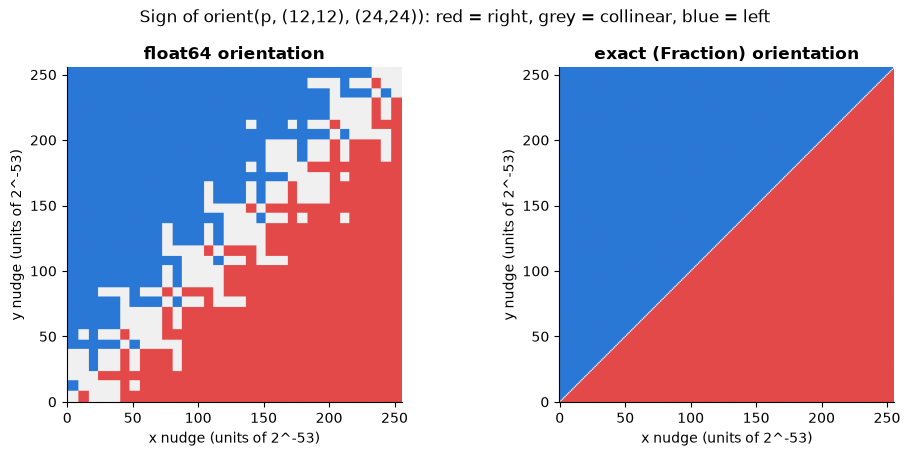

In [3]:
steps = np.arange(256) * 2.0 ** -53
px = 0.5 + steps[None, :] * np.ones((256, 1))                 # columns: x nudges
py = 0.5 + steps[:, None] * np.ones((1, 256))                 # rows: y nudges
q, r = (12.0, 12.0), (24.0, 24.0)
float_sign = np.sign((q[0] - px) * (r[1] - py) - (q[1] - py) * (r[0] - px))   # same formula, IEEE doubles
exact_sign = np.zeros_like(float_sign)
for i in range(256):
    for j in range(256):
        exact_sign[i, j] = np.sign(orient((Fraction(px[i, j]), Fraction(py[i, j])), (12, 12), (24, 24)))
wrong = np.mean(float_sign != exact_sign)
print(f"floating-point orientation has the wrong sign (or wrongly says 'collinear') in {wrong:.1%} of the 65,536 cases")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
cmap = plt.matplotlib.colors.ListedColormap([PALETTE[7], "#f0f0f0", PALETTE[0]])
for ax, img, title in [(axes[0], float_sign, "float64 orientation"), (axes[1], exact_sign, "exact (Fraction) orientation")]:
    ax.imshow(img, origin="lower", cmap=cmap, vmin=-1, vmax=1)
    ax.set(title=title, xlabel="x nudge (units of 2^-53)", ylabel="y nudge (units of 2^-53)"); ax.grid(False)
fig.suptitle("Sign of orient(p, (12,12), (24,24)): red = right, grey = collinear, blue = left")
plt.tight_layout(); plt.show()

**What just happened?** The exact picture (right) is cleanly split by the diagonal: points above $y = x$ are on the left. The floating-point picture (left) is a jagged staircase: a sizeable share of tiny perturbations (printed above) get the wrong sign or a false "collinear". A convex-hull or triangulation algorithm that trusts these signs can produce a non-convex "hull", crash, or loop forever.

> ⚠️ **Common mistake:** comparing floats with `==` or trusting `orient(...) == 0` on real-valued data. Fixes, from simplest to strongest: use **integer** (or `Fraction`) coordinates when you can; use a tolerance $\varepsilon$ (and accept that the result may be inconsistent); or use **exact/adaptive predicates** (Shewchuk's robust predicates, CGAL), which compute the sign exactly at near-float speed. See also floating point in [math in practice](../../14_Mathematics/08_industry_math_in_practice.ipynb).

---
## 2. Convex hull

> 💬 **In plain English:** find the tightest rubber band around a set of points.

**Intuition.** Hammer nails into a board at the points and stretch a rubber band around them all. When you let go, the band snaps to the **convex hull**: the smallest convex polygon containing every point.

**Definition.** The convex hull of a finite set $P$ is the smallest convex set containing $P$; it is a convex polygon whose corners (the **hull vertices**) are points of $P$. We output the vertices in counter-clockwise order.

**Andrew's monotone chain (1979).** Sort points by $(x, y)$. Build the **lower hull** left to right: push each point, but first pop the last point while the last two points and the new one do **not** make a left turn (orientation $\le 0$). Build the **upper hull** right to left the same way. Concatenate.

**Graham scan (1972).** Take the lowest point as anchor, sort the others by polar angle around it, then do the same "pop while not a left turn" scan.

Trace of the lower hull on 6 points (sorted by $x$):

| new point | stack before | action | stack after |
|---|---|---|---|
| (0,0) | [] | push | [(0,0)] |
| (1,2) | [(0,0)] | push | [(0,0),(1,2)] |
| (2,1) | [(0,0),(1,2)] | (0,0)→(1,2)→(2,1) is a right turn: pop (1,2) | [(0,0),(2,1)] |
| (3,0) | [(0,0),(2,1)] | right turn: pop (2,1) | [(0,0),(3,0)] |
| (4,3) | [(0,0),(3,0)] | left turn: push | [(0,0),(3,0),(4,3)] |

In [4]:
def monotone_chain(points):
    """Andrew's algorithm. Returns hull vertices in CCW order, without collinear boundary points."""
    pts = sorted(set(map(tuple, points)))
    if len(pts) <= 2:
        return pts
    lower = []
    for p in pts:
        while len(lower) >= 2 and orient(lower[-2], lower[-1], p) <= 0:
            lower.pop()                                   # not a left turn -> middle point is inside
        lower.append(p)
    upper = []
    for p in reversed(pts):
        while len(upper) >= 2 and orient(upper[-2], upper[-1], p) <= 0:
            upper.pop()
        upper.append(p)
    return lower[:-1] + upper[:-1]                        # last point of each list is the first of the other


def graham_scan(points):
    pts = list(set(map(tuple, points)))
    if len(pts) <= 2:
        return sorted(pts)
    anchor = min(pts, key=lambda p: (p[1], p[0]))         # lowest, then leftmost
    def by_angle(a, b):
        o = orient(anchor, a, b)
        if o != 0:
            return -1 if o > 0 else 1                     # a before b if b is to the left of anchor->a
        da = (a[0] - anchor[0]) ** 2 + (a[1] - anchor[1]) ** 2
        db = (b[0] - anchor[0]) ** 2 + (b[1] - anchor[1]) ** 2
        return -1 if da < db else (1 if da > db else 0)   # same angle: nearer first
    rest = sorted([p for p in pts if p != anchor], key=functools.cmp_to_key(by_angle))
    stack = [anchor]
    for p in rest:
        while len(stack) >= 2 and orient(stack[-2], stack[-1], p) <= 0:
            stack.pop()
        stack.append(p)
    return stack


def canon(hull):
    """Rotate a CCW vertex list to start at its smallest point, so two hulls can be compared."""
    i = hull.index(min(hull))
    return hull[i:] + hull[:i]


print("lower-hull example:", monotone_chain([(0, 0), (1, 2), (2, 1), (3, 0), (4, 3), (2, 4)]))
rng = np.random.default_rng(0)
for trial in range(300):
    n = int(rng.integers(3, 200))
    if trial % 2:
        P = [tuple(p) for p in rng.integers(0, 12, (n, 2)).tolist()]         # many duplicates and collinear points
    else:
        P = [tuple(p) for p in rng.normal(size=(n, 2)).tolist()]
    h1, h2 = monotone_chain(P), graham_scan(P)
    if len(h1) >= 3:
        assert canon(h1) == canon(h2)
        if trial % 2 == 0:                                                     # scipy/qhull on general-position floats
            assert set(h1) == {tuple(P[i]) for i in ConvexHull(np.array(P)).vertices}
    CHECKS["convex hull"] += 1
print(f"Andrew == Graham on {CHECKS['convex hull']} random sets; both == scipy.spatial.ConvexHull on the float sets")

lower-hull example: [(0, 0), (3, 0), (4, 3), (2, 4)]


Andrew == Graham on 300 random sets; both == scipy.spatial.ConvexHull on the float sets


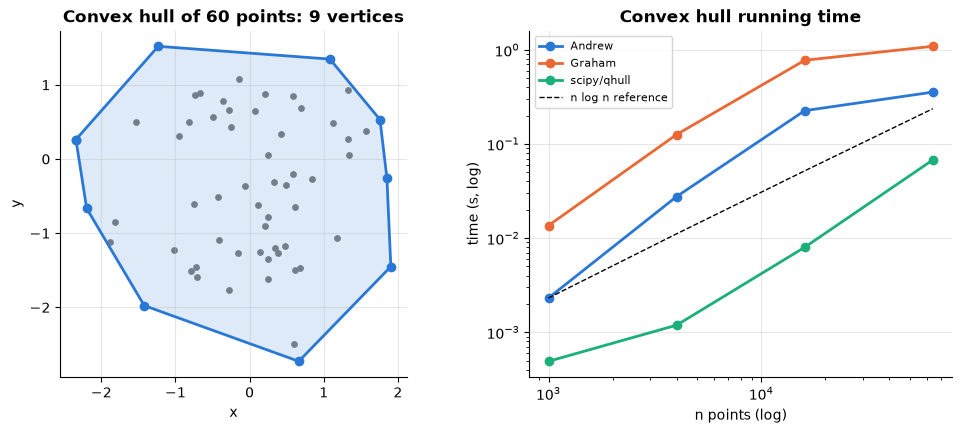

    n  Andrew (s)  Graham (s)  scipy/qhull (s)
 1000    0.002312    0.013601         0.000491
 4000    0.027621    0.126039         0.001188
16000    0.226016    0.775198         0.007990
64000    0.355720    1.091220         0.067710


In [5]:
P = rng.normal(size=(60, 2))
H = np.array(monotone_chain([tuple(p) for p in P]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(P[:, 0], P[:, 1], s=15, color="grey")
axes[0].fill(H[:, 0], H[:, 1], alpha=0.15, color=PALETTE[0])
axes[0].plot(np.r_[H[:, 0], H[0, 0]], np.r_[H[:, 1], H[0, 1]], "o-", color=PALETTE[0])
axes[0].set(title=f"Convex hull of 60 points: {len(H)} vertices", xlabel="x", ylabel="y"); axes[0].set_aspect("equal")

rows = []
for n in [1_000, 4_000, 16_000, 64_000]:
    pts = [tuple(p) for p in rng.normal(size=(n, 2)).tolist()]
    arr = np.array(pts)
    rows.append({"n": n, "Andrew (s)": best_time(monotone_chain, pts, repeat=2), "Graham (s)": best_time(graham_scan, pts, repeat=1),
                 "scipy/qhull (s)": best_time(ConvexHull, arr)})
T = pd.DataFrame(rows)
for col in ["Andrew (s)", "Graham (s)", "scipy/qhull (s)"]:
    axes[1].loglog(T.n, T[col], "o-", label=col[:-4])
axes[1].loglog(T.n, T.n * np.log2(T.n) * T["Andrew (s)"].iloc[0] / (T.n.iloc[0] * np.log2(T.n.iloc[0])), "k--", lw=1, label="n log n reference")
axes[1].set(xlabel="n points (log)", ylabel="time (s, log)", title="Convex hull running time"); axes[1].legend(fontsize=8)
plt.show()
print(T.to_string(index=False))

**What just happened?** Both from-scratch algorithms produced identical hulls on 300 random sets (half of them on a small integer grid full of duplicates and collinear points) and matched SciPy's Qhull on the floating-point sets. Andrew's algorithm runs in $O(n \log n)$ time, dominated by the sort: each point is pushed once and popped at most once, so the scan is $O(n)$. The comparator-based angular sort makes our Graham scan 2–4 times slower than Andrew's in Python; Qhull (C code) is far faster again.

| algorithm | time | idea |
|---|---|---|
| Graham scan | $O(n \log n)$ | sort by angle, stack scan |
| Andrew's monotone chain | $O(n \log n)$ | sort by $x$, lower + upper chains; no angles |
| Jarvis march (gift wrapping) | $O(nh)$ | repeatedly pick the most clockwise point; good when the hull size $h$ is tiny |
| Chan's algorithm | $O(n \log h)$ | output-sensitive and optimal |
| Quickhull (Qhull, SciPy) | $O(n \log n)$ expected | divide and conquer; also works in 3-D and higher |

> 🎓 **Exam / interview tip:** "Prove convex hull needs $\Omega(n \log n)$ comparisons." Reduce **sorting** to it: map numbers $x_i$ to points $(x_i, x_i^2)$ on a parabola; all are hull vertices, and reading the hull in order gives the numbers sorted. A faster hull would give a faster comparison sort, which is impossible.

---
## 3. Sweep-line algorithms

> 💬 **In plain English:** slide an imaginary line across the picture and only stop where something happens.

**Intuition.** Slide a vertical line across the plane from left to right, like a scanner. Stop only at interesting **events** (a segment starts, ends, or two segments cross) and keep a **status** structure describing what the line currently touches. Problems in 2-D become a sequence of simpler 1-D updates.

### 3.1 Interval overlap: how many meeting rooms?
Each meeting is an interval $[s, e)$. Sweep over time: a start is $+1$, an end is $-1$; the maximum running total is the number of rooms needed. Sort ends before starts at equal times, because a meeting ending at 10:00 frees its room for one starting at 10:00.

In [6]:
def rooms_needed(intervals):
    events = [(s, +1) for s, e in intervals] + [(e, -1) for s, e in intervals]
    events.sort(key=lambda t: (t[0], t[1]))               # -1 (end) sorts before +1 (start) at the same time
    cur = best = 0
    for _, delta in events:
        cur += delta
        best = max(best, cur)
    return best


def rooms_bruteforce(intervals):
    times = {s for s, e in intervals}
    return max((sum(s <= t < e for s, e in intervals) for t in times), default=0)


meetings = [(9, 10), (9.5, 11), (10, 11.5), (11, 12), (10.5, 12)]
print("rooms needed:", rooms_needed(meetings))
rr = random.Random(3)
for _ in range(2000):
    iv = []
    for _ in range(rr.randint(0, 15)):
        s = rr.randint(0, 20); iv.append((s, s + rr.randint(1, 6)))
    assert rooms_needed(iv) == rooms_bruteforce(iv)
    CHECKS["interval sweep"] += 1
print("sweep == brute force on 2,000 random schedules")

rooms needed: 3


sweep == brute force on 2,000 random schedules


**What just happened?** The five meetings need **3** rooms (around 10:30–11:00, three meetings overlap), and the $O(n \log n)$ sweep agreed with an $O(n^2)$ brute force on 2,000 random schedules.

### 3.2 Segment intersection: Bentley–Ottmann (simplified)
Given $n$ segments, report all $k$ intersection points. Checking every pair costs $O(n^2)$ even when $k$ is tiny. **Bentley–Ottmann (1979)** sweeps a vertical line and keeps the segments it crosses **sorted by $y$**. Key observation: two segments that intersect are **neighbours** in that order just before the intersection point. So we only test neighbours:

| event | what we do |
|---|---|
| left endpoint of $s$ | insert $s$ into the status; test $s$ against its new upper and lower neighbours |
| right endpoint of $s$ | remove $s$; test its former upper and lower neighbours against each other |
| intersection of $s, t$ | report it; **swap** $s$ and $t$; test each against its new outer neighbour |

Future intersections go into a priority queue of events ordered by $x$. With a balanced BST for the status the time is $O((n + k)\log n)$. **Simplifications** in our version: the status is a Python list (insert/delete $O(n)$ instead of $O(\log n)$), and we assume **general position** (no vertical segments, no three segments through one point, no shared endpoints), which holds with probability 1 for random real coordinates. Production versions must handle all the degenerate cases.

Bentley-Ottmann == all-pairs on 150 random segment sets


 n segments  intersections k  B-O pair tests  all-pairs tests
        100                2             142             4950
        200               13             403            19900
        400               41            1048            79800
        800              178            2511           319600


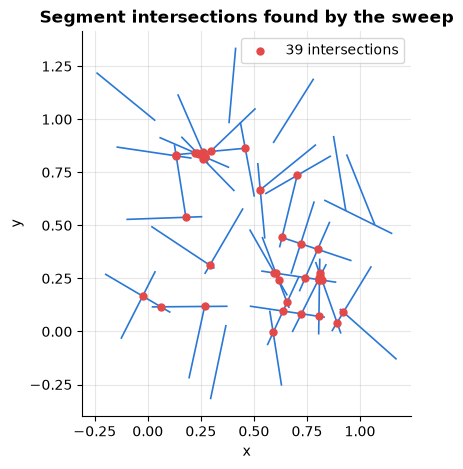

In [7]:
def seg_intersection_point(s, t):
    """Intersection point of segments s and t (proper crossing), or None."""
    (x1, y1), (x2, y2) = s; (x3, y3), (x4, y4) = t
    den = (x2 - x1) * (y4 - y3) - (y2 - y1) * (x4 - x3)
    if den == 0:
        return None
    ta = ((x3 - x1) * (y4 - y3) - (y3 - y1) * (x4 - x3)) / den
    tb = ((x3 - x1) * (y2 - y1) - (y3 - y1) * (x2 - x1)) / den
    if 0 <= ta <= 1 and 0 <= tb <= 1:
        return (x1 + ta * (x2 - x1), y1 + ta * (y2 - y1))
    return None


def bentley_ottmann(segments):
    segs = [tuple(sorted(s)) for s in segments]           # left endpoint first
    events = []                                           # (x, kind, i, j); kind 0 = start, 1 = crossing, 2 = end
    for i, (p, q) in enumerate(segs):
        heapq.heappush(events, (p[0], 0, i, -1))
        heapq.heappush(events, (q[0], 2, i, -1))
    status, scheduled, found = [], set(), []
    tests = 0

    def y_at(i, x):
        (x1, y1), (x2, y2) = segs[i]
        return y1 + (y2 - y1) * (x - x1) / (x2 - x1)

    def test(i, j, x):
        nonlocal tests
        tests += 1
        pt = seg_intersection_point(segs[i], segs[j])
        key = (min(i, j), max(i, j))
        if pt is not None and pt[0] > x and key not in scheduled:
            scheduled.add(key)
            heapq.heappush(events, (pt[0], 1, key[0], key[1]))   # a future crossing event

    while events:
        x, kind, i, j = heapq.heappop(events)
        if kind == 0:                                     # insert by y-order at the sweep position
            ys = [y_at(s, x) for s in status]
            pos = bisect.bisect(ys, segs[i][0][1])
            status.insert(pos, i)
            if pos > 0: test(status[pos - 1], i, x)
            if pos + 1 < len(status): test(i, status[pos + 1], x)
        elif kind == 2:                                   # remove; former neighbours become adjacent
            pos = status.index(i)
            status.pop(pos)
            if 0 < pos < len(status): test(status[pos - 1], status[pos], x)
        else:                                             # crossing: report and swap
            found.append(seg_intersection_point(segs[i], segs[j]))
            a, b = sorted((status.index(i), status.index(j)))
            assert b == a + 1, "crossing segments must be neighbours"
            status[a], status[b] = status[b], status[a]
            if a > 0: test(status[a - 1], status[a], x)
            if b + 1 < len(status): test(status[b], status[b + 1], x)
    return found, tests


def all_pairs(segments):
    pts = [seg_intersection_point(s, t) for s, t in itertools.combinations(segments, 2)]
    return [p for p in pts if p is not None]


rng = np.random.default_rng(7)
def random_segments(n, length):
    a = rng.uniform(0, 1, (n, 2))
    ang = rng.uniform(0, 2 * np.pi, n)
    b = a + length * np.c_[np.cos(ang), np.sin(ang)]
    return [(tuple(p), tuple(q)) for p, q in zip(a, b)]

for trial in range(150):
    S = random_segments(int(rng.integers(2, 60)), rng.uniform(0.05, 0.6))
    got, _ = bentley_ottmann(S)
    want = all_pairs(S)
    assert len(got) == len(want) and np.allclose(sorted(got), sorted(want))
    CHECKS["Bentley-Ottmann"] += 1
print(f"Bentley-Ottmann == all-pairs on {CHECKS['Bentley-Ottmann']} random segment sets")

rows = []
for n in [100, 200, 400, 800]:
    S = random_segments(n, 0.03)
    got, tests = bentley_ottmann(S)
    rows.append({"n segments": n, "intersections k": len(got), "B-O pair tests": tests, "all-pairs tests": n * (n - 1) // 2})
print(pd.DataFrame(rows).to_string(index=False))

S = random_segments(40, 0.35)
got, _ = bentley_ottmann(S)
fig, ax = plt.subplots(figsize=(6, 5))
for (p, q) in S:
    ax.plot([p[0], q[0]], [p[1], q[1]], color=PALETTE[0], lw=1.2)
if got:
    ax.scatter(*zip(*got), color=PALETTE[7], s=25, zorder=3, label=f"{len(got)} intersections")
ax.set(title="Segment intersections found by the sweep", xlabel="x", ylabel="y"); ax.legend(); ax.set_aspect("equal")
plt.show()

**What just happened?** On 150 random sets the sweep reported exactly the same intersection points as testing all pairs. The table shows why the sweep matters: with short segments (few intersections) the sweep's pair tests grow roughly in proportion to $n + k$ (2,511 tests for 800 segments with 178 crossings), while all-pairs grows quadratically (319,600 tests). The `assert b == a + 1` inside the code checks the key invariant: two segments are always neighbours in the status right before they cross.

**Complexity:** $O((n + k) \log n)$ time with a balanced BST status and a heap of events; $O(n + k)$ space (or $O(n)$ with care). Our list-based status makes each insert/delete $O(n)$.

---
## 4. Polygons: point-in-polygon and area

> 💬 **In plain English:** decide whether a point is inside a shape, and measure the shape's area.

**Point in polygon (ray casting).** Shoot a ray from the point to the right. Every time the ray crosses the polygon boundary you switch between outside and inside. **Odd** number of crossings means **inside** (the even–odd rule). Used in maps ("which country is this GPS point in?"), games (clicks on shapes) and geofencing.

**Shoelace formula.** For a polygon with vertices $(x_0,y_0), \dots, (x_{n-1}, y_{n-1})$ in order,
$$\text{Area} = \frac12 \left| \sum_{i=0}^{n-1} \left(x_i y_{i+1} - x_{i+1} y_i\right) \right| \quad (\text{indices mod } n).$$
Without the absolute value the sum is positive for counter-clockwise order and negative for clockwise: the same sign idea as `orient`. Worked example, the square (0,0), (2,0), (2,2), (0,2): terms $0\cdot0 - 2\cdot0 = 0$, $2\cdot2 - 2\cdot0 = 4$, $2\cdot2 - 0\cdot2 = 4$, $0\cdot0 - 0\cdot2 = 0$; area $= \frac12 \cdot 8 = 4$ ✓.

square area: 4.0 | signed (CCW): 4.0 | signed (CW): -4.0


ray casting == matplotlib Path.contains_points on 30,000 points; shoelace == signed triangle-fan area on 100 polygons


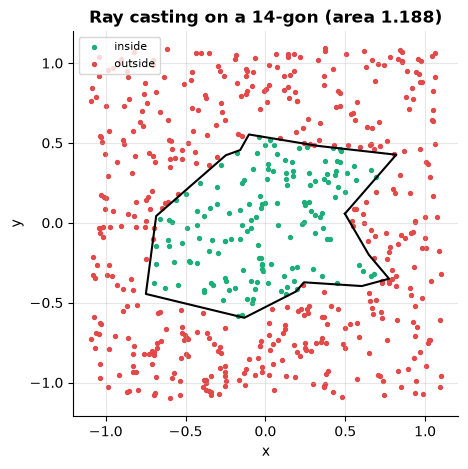

In [8]:
def point_in_polygon(pt, poly):
    """Even-odd ray casting to the right. Points exactly on the boundary are not handled specially."""
    x, y = pt
    inside = False
    n = len(poly)
    for i in range(n):
        (x1, y1), (x2, y2) = poly[i], poly[(i + 1) % n]
        if (y1 > y) != (y2 > y):                           # edge straddles the horizontal line through pt
            x_cross = x1 + (y - y1) * (x2 - x1) / (y2 - y1)
            if x_cross > x:                                # crossing is to the right of pt
                inside = not inside
    return inside


def shoelace(poly, signed=False):
    s = sum(poly[i][0] * poly[(i + 1) % len(poly)][1] - poly[(i + 1) % len(poly)][0] * poly[i][1] for i in range(len(poly)))
    return s / 2 if signed else abs(s) / 2


def random_star_polygon(rng, n):
    ang = np.sort(rng.uniform(0, 2 * np.pi, n))
    rad = rng.uniform(0.3, 1.0, n)
    return [(r * np.cos(a), r * np.sin(a)) for r, a in zip(rad, ang)]


print("square area:", shoelace([(0, 0), (2, 0), (2, 2), (0, 2)]), "| signed (CCW):", shoelace([(0, 0), (2, 0), (2, 2), (0, 2)], True),
      "| signed (CW):", shoelace([(0, 2), (2, 2), (2, 0), (0, 0)], True))
rng = np.random.default_rng(9)
for trial in range(100):
    poly = random_star_polygon(rng, int(rng.integers(3, 25)))
    pts = rng.uniform(-1.1, 1.1, (300, 2))
    ours = np.array([point_in_polygon(p, poly) for p in pts])
    ref = Path(poly).contains_points(pts)
    assert (ours == ref).all()
    fan = abs(sum(orient((0, 0), poly[i], poly[(i + 1) % len(poly)]) for i in range(len(poly)))) / 2   # signed triangle fan from the origin
    assert math.isclose(shoelace(poly), fan, rel_tol=1e-9)
    CHECKS["point in polygon"] += 300; CHECKS["shoelace area"] += 1
print("ray casting == matplotlib Path.contains_points on 30,000 points; shoelace == signed triangle-fan area on 100 polygons")

poly = random_star_polygon(rng, 14)
pts = rng.uniform(-1.1, 1.1, (600, 2))
ins = np.array([point_in_polygon(p, poly) for p in pts])
fig, ax = plt.subplots(figsize=(5, 5))
P_ = np.array(poly + [poly[0]])
ax.plot(P_[:, 0], P_[:, 1], color="black", lw=1.5)
ax.scatter(pts[ins, 0], pts[ins, 1], s=8, color=PALETTE[2], label="inside")
ax.scatter(pts[~ins, 0], pts[~ins, 1], s=8, color=PALETTE[7], label="outside")
ax.set(title=f"Ray casting on a 14-gon (area {shoelace(poly):.3f})", xlabel="x", ylabel="y"); ax.set_aspect("equal"); ax.legend(fontsize=8)
plt.show()

**What just happened?** The square's area is 4, positive when listed counter-clockwise and negative when listed clockwise. Ray casting agreed with matplotlib's `Path.contains_points` on 30,000 random points against 100 random non-convex polygons, and the shoelace area matched a sum of **signed** triangle areas fanned out from the origin (triangles outside the polygon cancel out).

**Complexity:** both are $O(n)$ for an $n$-vertex polygon. For many queries against the same convex polygon, binary search on the angle gives $O(\log n)$ per query.

> ⚠️ **Common mistake:** in ray casting, counting a crossing twice when the ray passes exactly through a vertex. The half-open test `(y1 > y) != (y2 > y)` counts each vertex for exactly one of its two edges, which fixes it.

---
## 5. Voronoi diagrams and Delaunay triangulations

> 💬 **In plain English:** split the map into "closest to this point" regions and connect neighbouring points into triangles.

**Intuition.** Put a coffee shop at each point (the **sites**). Colour every location on the map by the shop closest to it. The coloured regions are the **Voronoi cells**: a city's "nearest hospital" map, a phone network's coverage map, or the territory of each shop.

**Definitions.**
- The **Voronoi cell** of site $p_i$ is $\{x : \|x - p_i\| \le \|x - p_j\| \text{ for all } j\}$. Cells are convex polygons; their edges lie on perpendicular bisectors between sites.
- The **Delaunay triangulation** connects two sites whenever their Voronoi cells share an edge (it is the **dual graph**). Its defining property: the circumscribed circle of every triangle contains **no other site** (the **empty-circle property**). Among all triangulations it maximises the smallest angle, so it avoids skinny triangles, which is why mesh generators use it.
- Both can be built in $O(n \log n)$ (Fortune's sweep for Voronoi; divide and conquer or randomized incremental for Delaunay). SciPy wraps Qhull.

**In-circle test** (exact like `orient`): for a CCW triangle $a, b, c$, point $d$ is strictly inside the circumcircle iff
$$\det\begin{pmatrix} a_x - d_x & a_y - d_y & (a_x - d_x)^2 + (a_y - d_y)^2 \\ b_x - d_x & b_y - d_y & (b_x - d_x)^2 + (b_y - d_y)^2 \\ c_x - d_x & c_y - d_y & (c_x - d_x)^2 + (c_y - d_y)^2 \end{pmatrix} > 0.$$

In [9]:
def in_circle(a, b, c, d):
    """> 0 iff d is strictly inside the circumcircle of CCW triangle abc."""
    rows = [(p[0] - d[0], p[1] - d[1]) for p in (a, b, c)]
    M = [[dx, dy, dx * dx + dy * dy] for dx, dy in rows]
    return (M[0][0] * (M[1][1] * M[2][2] - M[1][2] * M[2][1]) - M[0][1] * (M[1][0] * M[2][2] - M[1][2] * M[2][0])
            + M[0][2] * (M[1][0] * M[2][1] - M[1][1] * M[2][0]))


rng = np.random.default_rng(12)
sites = rng.uniform(0, 1, (40, 2))
tri = Delaunay(sites)
violations = 0
for simplex in tri.simplices:
    a, b, c = (tuple(sites[i]) for i in simplex)
    if orient(a, b, c) < 0:
        b, c = c, b                                        # make it counter-clockwise
    for k in range(len(sites)):
        if k not in simplex and in_circle(a, b, c, tuple(sites[k])) > 1e-12:
            violations += 1
print(f"{len(tri.simplices)} Delaunay triangles, empty-circle violations: {violations}")
assert violations == 0

# The Euclidean minimum spanning tree is a subgraph of the Delaunay triangulation
G = nx.Graph()
for i, j in itertools.combinations(range(len(sites)), 2):
    G.add_edge(i, j, weight=float(np.linalg.norm(sites[i] - sites[j])))
mst = {tuple(sorted(e)) for e in nx.minimum_spanning_tree(G).edges()}
del_edges = {tuple(sorted((s[i], s[(i + 1) % 3]))) for s in tri.simplices for i in range(3)}
print(f"MST edges inside Delaunay edges: {len(mst & del_edges)}/{len(mst)}  (Delaunay has {len(del_edges)} edges vs {len(sites) * 39 // 2} in the complete graph)")
assert mst <= del_edges

69 Delaunay triangles, empty-circle violations: 0
MST edges inside Delaunay edges: 39/39  (Delaunay has 108 edges vs 780 in the complete graph)


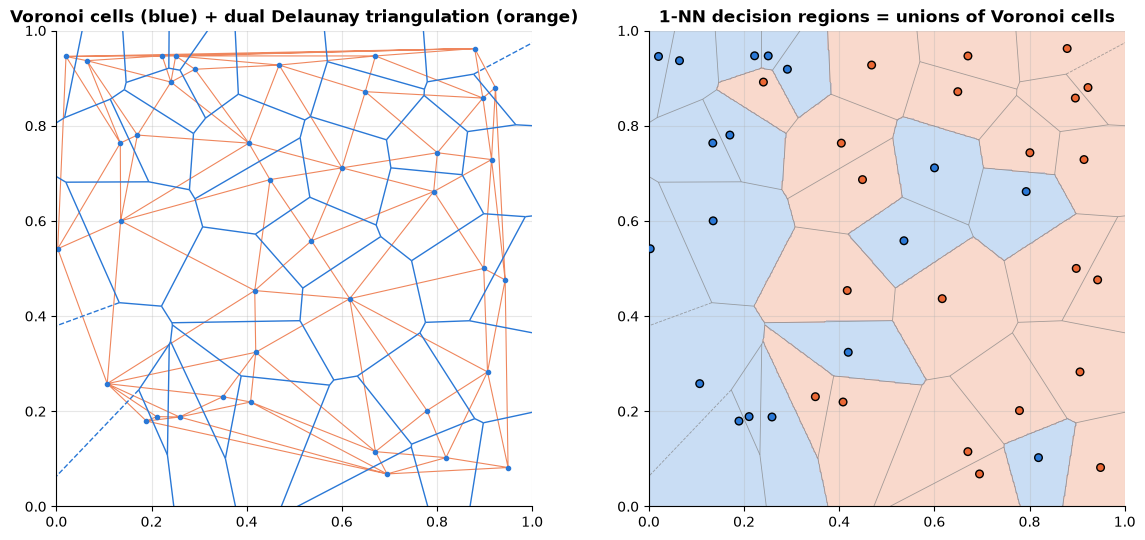

In [10]:
from sklearn.neighbors import KNeighborsClassifier

labels = (sites[:, 0] + 0.3 * rng.normal(size=len(sites)) > 0.5).astype(int)   # two classes
knn = KNeighborsClassifier(n_neighbors=1).fit(sites, labels)
gx, gy = np.meshgrid(np.linspace(0, 1, 300), np.linspace(0, 1, 300))
pred = knn.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
vor = Voronoi(sites)
voronoi_plot_2d(vor, ax=axes[0], show_vertices=False, line_colors=PALETTE[0], line_width=1, point_size=6)
axes[0].triplot(sites[:, 0], sites[:, 1], tri.simplices, color=PALETTE[1], lw=0.8, alpha=0.8)
axes[0].set(xlim=(0, 1), ylim=(0, 1), title="Voronoi cells (blue) + dual Delaunay triangulation (orange)")
axes[0].set_aspect("equal")
axes[1].contourf(gx, gy, pred, levels=[-0.5, 0.5, 1.5], colors=[PALETTE[0], PALETTE[1]], alpha=0.25)
voronoi_plot_2d(vor, ax=axes[1], show_vertices=False, line_colors="grey", line_width=0.6, point_size=0, line_alpha=0.7)
axes[1].scatter(sites[:, 0], sites[:, 1], c=[PALETTE[l] for l in labels], s=30, edgecolor="black", zorder=3)
axes[1].set(xlim=(0, 1), ylim=(0, 1), title="1-NN decision regions = unions of Voronoi cells")
axes[1].set_aspect("equal")
plt.tight_layout(); plt.show()

**What just happened?**
- SciPy's Delaunay triangulation of 40 random sites passed our exact-formula empty-circle test for every triangle and every other site.
- The **Euclidean minimum spanning tree** used only Delaunay edges. That is a theorem, and it is how the Euclidean MST is computed in $O(n \log n)$: build Delaunay ($O(n)$ edges), then run Kruskal on those edges instead of on all $\binom{n}{2}$ pairs.
- Right: the **1-nearest-neighbour classifier** ([KNN notebook](../../03_Machine_Learning/01_supervised/07_knn.ipynb)) colours each Voronoi cell with the label of its site, so its decision boundary is made of Voronoi edges between differently-labelled neighbours. That is why 1-NN boundaries look jagged and why noisy labels create little islands.

The **closest pair** of points is always a Delaunay edge too; the $O(n \log n)$ divide-and-conquer algorithm is in [`dsa/08`](../dsa/08_greedy_and_divide_and_conquer.ipynb).

---
## 6. The fast Fourier transform from scratch

> 💬 **In plain English:** multiply long lists of numbers fast by switching to a form where multiplying is easy.

**Intuition.** Multiplying two polynomials of degree $n$ the school way costs $n^2$ multiplications. But a polynomial of degree $< n$ is also fully described by its **values at $n$ points**, and in that "value form" multiplication is easy: just multiply the values point by point ($n$ multiplications). So: (1) evaluate both polynomials at $2n$ points, (2) multiply pointwise, (3) convert back. Steps 1 and 3 are expensive at random points, but at the **complex roots of unity** they can be done in $O(n \log n)$ by the **fast Fourier transform**.

### 6.1 Roots of unity and the DFT
The $n$-th roots of unity are $\omega_n^k = e^{2\pi i k/n}$, $k = 0, \dots, n-1$: $n$ equally spaced points on the unit circle. The **discrete Fourier transform** (DFT) of $a = (a_0, \dots, a_{n-1})$ is
$$A_k = \sum_{j=0}^{n-1} a_j\, \omega_n^{-jk}, \qquad k = 0, \dots, n-1,$$
i.e. the polynomial $a(x) = \sum_j a_j x^j$ evaluated at $\omega_n^{-k}$ (NumPy's sign convention). Computed directly it costs $O(n^2)$.

### 6.2 Cooley–Tukey divide and conquer
Split $a(x)$ into even and odd coefficients: $a(x) = a_{\text{even}}(x^2) + x\, a_{\text{odd}}(x^2)$. Squaring the $n$ roots of unity gives only $n/2$ distinct values (the $n/2$-th roots), so both halves need only a **size-$n/2$ DFT**. The **butterfly** combines them, using $\omega^{k + n/2} = -\omega^k$:
$$A_k = E_k + \omega_n^{-k} O_k, \qquad A_{k + n/2} = E_k - \omega_n^{-k} O_k.$$
Recurrence $T(n) = 2T(n/2) + O(n)$, so $T(n) = O(n \log n)$ by the Master theorem ([`dsa/01`](../dsa/01_complexity_analysis_and_recursion.ipynb)). This is the 1965 Cooley–Tukey algorithm (Gauss had the idea around 1805).

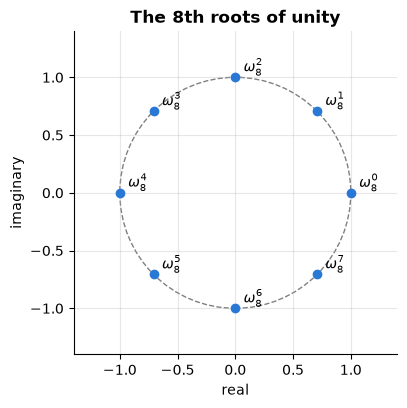

our fft == np.fft.fft and ifft(fft(x)) == x for n = 1..512; naive DFT agrees too


In [11]:
def dft_naive(a):
    n = len(a)
    return [sum(a[j] * cmath.exp(-2j * math.pi * j * k / n) for j in range(n)) for k in range(n)]


def fft(a):
    """Recursive radix-2 Cooley-Tukey. len(a) must be a power of two."""
    n = len(a)
    if n == 1:
        return [complex(a[0])]
    even, odd = fft(a[0::2]), fft(a[1::2])               # two half-size DFTs
    out = [0j] * n
    for k in range(n // 2):
        t = cmath.exp(-2j * math.pi * k / n) * odd[k]     # twiddle factor * odd part
        out[k] = even[k] + t                              # butterfly
        out[k + n // 2] = even[k] - t
    return out


def ifft(A):
    """Inverse via conjugation: ifft(A) = conj(fft(conj(A))) / n."""
    n = len(A)
    return [x.conjugate() / n for x in fft([y.conjugate() for y in A])]


fig, ax = plt.subplots(figsize=(4.2, 4.2))
w = [cmath.exp(2j * math.pi * k / 8) for k in range(8)]
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey", ls="--"))
ax.scatter([z.real for z in w], [z.imag for z in w], color=PALETTE[0], zorder=3)
for k, z in enumerate(w):
    ax.annotate(f"$\\omega_8^{k}$", (z.real, z.imag), textcoords="offset points", xytext=(6, 4))
ax.set(xlim=(-1.4, 1.4), ylim=(-1.4, 1.4), title="The 8th roots of unity", xlabel="real", ylabel="imaginary"); ax.set_aspect("equal")
plt.show()

for n in [1, 2, 4, 8, 64, 512]:
    x = np.random.default_rng(n).normal(size=n) + 1j * np.random.default_rng(n + 1).normal(size=n)
    assert np.allclose(fft(list(x)), np.fft.fft(x)) and np.allclose(ifft(fft(list(x))), x)
    if n <= 64:
        assert np.allclose(dft_naive(list(x)), np.fft.fft(x))
    CHECKS["FFT vs numpy"] += 1
print("our fft == np.fft.fft and ifft(fft(x)) == x for n = 1..512; naive DFT agrees too")

### 6.3 Polynomial multiplication
Worked example: $(1 + 2x)(3 + x) = 3 + 7x + 2x^2$. The product has 3 coefficients, so pad both inputs to length 4 (a power of two $\ge 3$), transform, multiply pointwise, transform back, round.

values of (1+2x) at the 4 points: [ 3.+0.j  1.-2.j -1.+0.j  1.+2.j]
values of (3+x)  at the 4 points: [4.+0.j 3.-1.j 2.+0.j 3.+1.j]
pointwise products              : [12.+0.j  1.-7.j -2.+0.j  1.+7.j]
back to coefficients            : [3, 7, 2]  expected [3, 7, 2]


   n  naive Python O(n^2)  our FFT O(n log n)  np.convolve (C, direct)  np.fft (C, FFT)
  64             6.89e-04            6.68e-03                 9.78e-06         4.98e-05
 128             7.64e-03            1.15e-02                 2.35e-05         5.47e-05
 256             4.87e-02            2.74e-02                 8.49e-05         6.27e-05
 512             2.14e-01            5.92e-02                 2.84e-04         8.09e-05
1024             9.90e-01            1.47e-01                 1.10e-03         1.45e-04
2048             3.93e+00            3.24e-01                 1.37e-02         1.95e-04
4096                  NaN            6.73e-01                 8.29e-02         4.76e-04


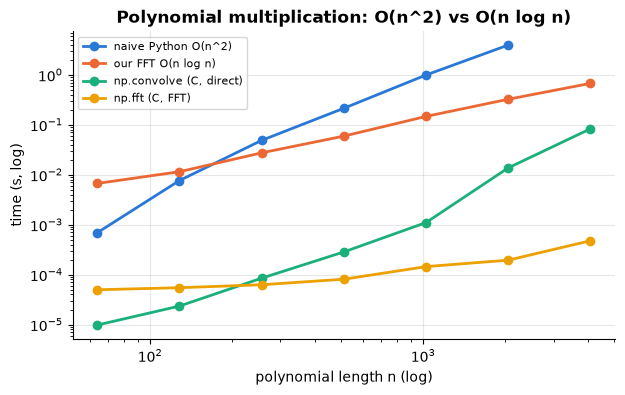

In [12]:
def poly_mult_naive(a, b):
    out = [0] * (len(a) + len(b) - 1)
    for i, ai in enumerate(a):
        for j, bj in enumerate(b):
            out[i + j] += ai * bj                         # n*m multiplications
    return out


def poly_mult_fft(a, b):
    m = len(a) + len(b) - 1
    n = 1 << (m - 1).bit_length()                         # next power of two >= m
    fa, fb = fft(list(a) + [0] * (n - len(a))), fft(list(b) + [0] * (n - len(b)))
    prod = ifft([x * y for x, y in zip(fa, fb)])          # pointwise product in "value form"
    return [round(c.real) for c in prod[:m]]              # integer inputs -> round away float noise


A, B = fft([1, 2, 0, 0]), fft([3, 1, 0, 0])
print("values of (1+2x) at the 4 points:", np.round(A, 3))
print("values of (3+x)  at the 4 points:", np.round(B, 3))
print("pointwise products              :", np.round([x * y for x, y in zip(A, B)], 3))
print("back to coefficients            :", poly_mult_fft([1, 2], [3, 1]), " expected", poly_mult_naive([1, 2], [3, 1]))

rr = random.Random(5)
for _ in range(300):
    a = [rr.randint(-50, 50) for _ in range(rr.randint(1, 80))]
    b = [rr.randint(-50, 50) for _ in range(rr.randint(1, 80))]
    assert poly_mult_fft(a, b) == poly_mult_naive(a, b)
    CHECKS["FFT polynomial multiplication"] += 1

rows = []
for n in [64, 128, 256, 512, 1024, 2048, 4096]:
    a = [rr.randint(0, 9) for _ in range(n)]; b = [rr.randint(0, 9) for _ in range(n)]
    rows.append({"n": n,
                 "naive Python O(n^2)": best_time(poly_mult_naive, a, b, repeat=1) if n <= 2048 else np.nan,
                 "our FFT O(n log n)": best_time(poly_mult_fft, a, b, repeat=1),
                 "np.convolve (C, direct)": best_time(np.convolve, np.array(a), np.array(b)),
                 "np.fft (C, FFT)": best_time(lambda x, y: np.fft.irfft(np.fft.rfft(x, 2 * n) * np.fft.rfft(y, 2 * n), 2 * n), np.array(a), np.array(b))})
Tm = pd.DataFrame(rows)
print(Tm.to_string(index=False, float_format=lambda v: f"{v:.2e}"))
fig, ax = plt.subplots(figsize=(7, 4))
for col in Tm.columns[1:]:
    ax.loglog(Tm.n, Tm[col], "o-", label=col)
ax.set(xlabel="polynomial length n (log)", ylabel="time (s, log)", title="Polynomial multiplication: O(n^2) vs O(n log n)"); ax.legend(fontsize=8)
plt.show()

**What just happened?** The four values of each polynomial were multiplied pointwise and the inverse FFT returned $[3, 7, 2, 0]$, i.e. $3 + 7x + 2x^2$. On 300 random integer polynomials the FFT product equalled the schoolbook product exactly. In the timing plot, the naive Python line has slope about 2 on the log-log axes (quadratic) and our Python FFT has slope just above 1; somewhere in the hundreds the pure-Python FFT overtakes the pure-Python schoolbook method (see the table). Compiled code shifts the constants (NumPy's direct `np.convolve` is fast for short inputs) but not the slopes: for long inputs, FFT wins.

> ⚠️ **Common mistake:** forgetting to **pad** to length $\ge n + m - 1$. Without padding the FFT computes a **circular** convolution: the high-degree coefficients wrap around and are added to the low ones (Section 7 shows this).

---
## 7. The convolution theorem: signals, CNNs and big integers

> 💬 **In plain English:** sliding a filter over a signal is a multiplication in disguise, so the FFT speeds it up.

**Convolution** of sequences $a$ and $b$: $(a * b)_k = \sum_j a_j\, b_{k-j}$. It is exactly polynomial multiplication, and also: a moving average, a blur filter, an echo, a CNN layer. The **convolution theorem**:
$$\mathcal{F}(a * b) = \mathcal{F}(a) \cdot \mathcal{F}(b) \qquad\Longrightarrow\qquad a * b = \mathcal{F}^{-1}\big(\mathcal{F}(a)\cdot\mathcal{F}(b)\big).$$

Three facts worth checking in code:
1. Without zero padding you get **circular** convolution.
2. A "convolution" layer in deep learning (`torch.nn.functional.conv1d`) actually computes **cross-correlation** (no kernel flip); flipping the kernel turns it into a true convolution.
3. Direct convolution costs $O(nm)$; FFT convolution costs $O((n + m)\log(n + m))$, so FFT wins for long kernels.

In [13]:
x = np.array([1.0, 2, 3, 4])
k = np.array([1.0, 1, 1])
linear = np.convolve(x, k)                                          # length 4 + 3 - 1 = 6
circular = np.real(np.fft.ifft(np.fft.fft(x) * np.fft.fft(k, 4)))   # no padding: length 4
padded = np.real(np.fft.ifft(np.fft.fft(x, 6) * np.fft.fft(k, 6)))
print("np.convolve (linear)  :", linear)
print("FFT, no padding       :", circular.round(6), "<- the tail [7, 4] wrapped onto the start")
print("FFT, padded to 6      :", padded.round(6))

try:
    import torch
    torch.set_num_threads(2)
    sig = torch.tensor(x).view(1, 1, -1)
    ker = torch.tensor([1.0, 2.0, 3.0], dtype=torch.float64)
    xcorr = torch.nn.functional.conv1d(sig, ker.view(1, 1, -1), padding=2).flatten().numpy()
    true_conv = torch.nn.functional.conv1d(sig, ker.flip(0).view(1, 1, -1), padding=2).flatten().numpy()
    print("\nkernel [1, 2, 3]:")
    print("torch conv1d (no flip)  :", xcorr, " == np.correlate:", np.allclose(xcorr, np.correlate(x, [1.0, 2, 3], mode="full")))
    print("torch conv1d (flipped)  :", true_conv, " == np.convolve:", np.allclose(true_conv, np.convolve(x, [1.0, 2, 3])))
except ImportError:
    print("torch not installed: skipping the CNN comparison (optional)")

rows = []
sig_long = np.random.default_rng(0).normal(size=50_000)
for m in [4, 16, 64, 256, 1024, 4096]:
    ker = np.random.default_rng(m).normal(size=m)
    t_direct = best_time(np.convolve, sig_long, ker)
    t_fft = best_time(signal.fftconvolve, sig_long, ker)
    assert np.allclose(np.convolve(sig_long, ker), signal.fftconvolve(sig_long, ker))
    rows.append({"kernel length m": m, "direct np.convolve (ms)": 1e3 * t_direct, "scipy fftconvolve (ms)": 1e3 * t_fft})
print("\nsignal length 50,000:")
print(pd.DataFrame(rows).round(3).to_string(index=False))

np.convolve (linear)  : [1. 3. 6. 9. 7. 4.]
FFT, no padding       : [8. 7. 6. 9.] <- the tail [7, 4] wrapped onto the start
FFT, padded to 6      : [1. 3. 6. 9. 7. 4.]



kernel [1, 2, 3]:
torch conv1d (no flip)  : [ 3.  8. 14. 20. 11.  4.]  == np.correlate: True
torch conv1d (flipped)  : [ 1.  4. 10. 16. 17. 12.]  == np.convolve: True



signal length 50,000:
 kernel length m  direct np.convolve (ms)  scipy fftconvolve (ms)
               4                    0.112                   3.268
              16                    1.674                   5.492
              64                    1.920                   6.284
             256                    6.390                   3.442
            1024                   12.317                   4.879
            4096                   68.380                   3.880


**What just happened?**
- Unpadded FFT convolution gave $[8, 7, 6, 9]$ instead of the first four entries $[1, 3, 6, 9]$ of the true result: the last two outputs (7 and 4) wrapped around and were added to the first two.
- PyTorch's `conv1d` matched `np.correlate` (cross-correlation), and matched `np.convolve` only after flipping the kernel. For a learned CNN this makes no difference (the network simply learns the flipped kernel), but it matters when you load a hand-designed filter.
- With a 50,000-sample signal, direct convolution time grows linearly with the kernel length while FFT convolution stays nearly flat; for long kernels FFT is much faster (see the table). `scipy.signal.convolve(method="auto")` chooses between the two for you.

### Big-integer multiplication
A number is a polynomial evaluated at its base: $1234 = 4 + 3\cdot10 + 2\cdot10^2 + 1\cdot10^3$. So: digits → FFT polynomial product → **carry**. Schönhage–Strassen (1971) made this $O(n \log n \log\log n)$, and Harvey & van der Hoeven (2019) reached $O(n \log n)$. Python's own `int` uses Karatsuba for large numbers.

In [14]:
sys.set_int_max_str_digits(100_000)   # Python 3.11+ refuses int<->str conversions above 4,300 digits by default (a DoS guard)


def big_multiply(x, y):
    a = [int(d) for d in reversed(str(x))]                # least-significant digit first
    b = [int(d) for d in reversed(str(y))]
    m = len(a) + len(b) - 1
    n = 1 << (m - 1).bit_length()
    prod = np.fft.irfft(np.fft.rfft(a, n) * np.fft.rfft(b, n), n)[:m]
    coeffs = np.rint(prod).astype(np.int64)               # exact as long as float error < 0.5
    digits, carry = [], 0
    for c in coeffs:                                      # propagate carries
        carry += int(c)
        digits.append(carry % 10)
        carry //= 10
    while carry:
        digits.append(carry % 10); carry //= 10
    return int("".join(map(str, reversed(digits))))


rr = random.Random(8)
for _ in range(200):
    x_ = rr.randrange(10 ** rr.randint(1, 3000)); y_ = rr.randrange(10 ** rr.randint(1, 3000))
    assert big_multiply(x_, y_) == x_ * y_
    CHECKS["FFT big-integer multiply"] += 1
x_, y_ = 3 ** 2000, 7 ** 1500
print(f"3^2000 * 7^1500 has {len(str(x_ * y_))} digits; FFT result correct: {big_multiply(x_, y_) == x_ * y_}")

3^2000 * 7^1500 has 2222 digits; FFT result correct: True


**What just happened?** FFT multiplication matched Python's exact integer multiplication on 200 random numbers with up to 3,000 digits. With base-10 digits the coefficients stay small enough for double precision to round correctly; for millions of digits the floating-point error would exceed 0.5, which is why serious libraries use the **number-theoretic transform** (an FFT over integers modulo a prime: no rounding at all) or split the numbers carefully.

---
## 8. 🔗 How this connects to modern AI

> 💬 **In plain English:** the same tricks power long-sequence models, speech spectrograms, vision and robotics.

### 8.1 Long convolutions in sequence models
Attention compares every token with every other token: $O(L^2)$ for a sequence of length $L$. Structured state-space models (**S4**, Gu et al., 2021) and **Hyena** (Poli et al., 2023) instead apply a **convolution whose kernel is as long as the sequence**. Done directly that is also $O(L^2)$, but with the FFT it is $O(L \log L)$, which is what makes very long contexts affordable for these architectures. (Mamba, a later SSM, uses a parallel scan instead, but the convolution view explains why such models can be trained efficiently.) See [LLM architecture innovations](../../08_LLM/14_llm_architecture_innovations.ipynb).

In [15]:
rows = []
for L in [512, 1024, 2048, 4096, 8192]:
    u = np.random.default_rng(L).normal(size=L)                     # one channel of a sequence
    kern = np.exp(-np.arange(L) / (L / 8)) * np.cos(np.arange(L) / 5) # a long, smoothly decaying kernel
    t_direct = best_time(np.convolve, u, kern, repeat=2)
    t_fft = best_time(lambda a, b: np.fft.irfft(np.fft.rfft(a, 2 * L) * np.fft.rfft(b, 2 * L), 2 * L)[:L], u, kern, repeat=3)
    y_fft = np.fft.irfft(np.fft.rfft(u, 2 * L) * np.fft.rfft(kern, 2 * L), 2 * L)[:L]
    assert np.allclose(y_fft, np.convolve(u, kern)[:L])              # causal convolution, same result
    rows.append({"sequence length L": L, "direct O(L^2) (ms)": 1e3 * t_direct, "FFT O(L log L) (ms)": 1e3 * t_fft,
                 "speed-up": t_direct / t_fft})
print(pd.DataFrame(rows).round(2).to_string(index=False))

 sequence length L  direct O(L^2) (ms)  FFT O(L log L) (ms)  speed-up
               512                0.13                 0.15      0.86
              1024                0.37                 0.23      1.65
              2048                1.28                 0.31      4.15
              4096                5.99                 0.57     10.48
              8192              114.23                 0.81    141.71


**What just happened?** For a sequence-long kernel the FFT gives the same causal output as direct convolution, and the speed-up grows with $L$ (see the last column), exactly the $L^2$ vs $L \log L$ gap: doubling $L$ makes direct convolution about 4× slower but FFT convolution only a little more than 2× slower. (Timings on a busy machine are noisy; the trend is what matters.)

### 8.2 Spectrograms for speech and audio models
Speech models (Whisper and most ASR systems) do not read raw waveforms; they read a **spectrogram**: the signal is cut into short overlapping frames, each frame is multiplied by a window and FFT'd, and the magnitudes are stacked over time. This is the **short-time Fourier transform (STFT)**. Below we build one from scratch for a "chirp" whose pitch rises over time, and check it against `scipy.signal.stft`. See [speech and audio](../../07_NLP/08_speech_and_audio.ipynb) for mel spectrograms and ASR.

spectrogram shape (129, 124) (frequency bins x frames); matches scipy.signal.stft


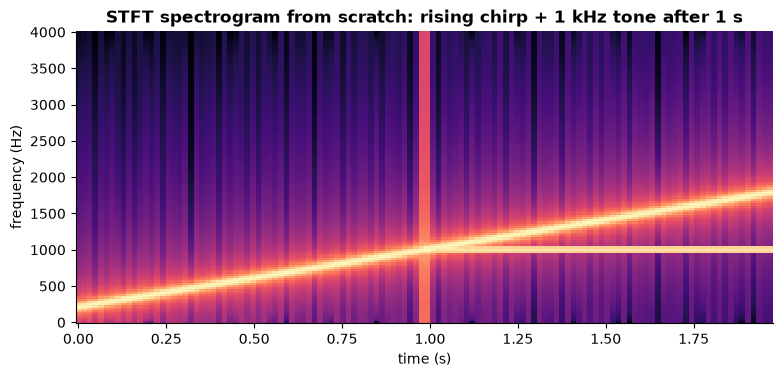

In [16]:
fs = 8000                                                   # samples per second
t = np.arange(0, 2.0, 1 / fs)
chirp = np.sin(2 * np.pi * (200 * t + 400 * t ** 2))        # frequency rises from 200 Hz to 1,800 Hz
chirp += 0.5 * np.sin(2 * np.pi * 1000 * t) * (t > 1.0)     # a steady 1 kHz tone joins after 1 s


def stft_scratch(x, n_fft=256, hop=128):
    window = np.hanning(n_fft + 1)[:-1]                     # periodic Hann window
    frames = [x[i:i + n_fft] * window for i in range(0, len(x) - n_fft + 1, hop)]
    return np.abs(np.array([np.fft.rfft(f) for f in frames])).T   # (frequency bins, time frames)


S = stft_scratch(chirp)
f_ref, t_ref, Z = signal.stft(chirp, fs=fs, window="hann", nperseg=256, noverlap=128, boundary=None, padded=False)
ref = np.abs(Z) * np.hanning(257)[:-1].sum()               # scipy scales by 1/sum(window)
assert np.allclose(S, ref, atol=1e-6)
print(f"spectrogram shape {S.shape} (frequency bins x frames); matches scipy.signal.stft")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.pcolormesh(np.arange(S.shape[1]) * 128 / fs, np.fft.rfftfreq(256, 1 / fs), 20 * np.log10(S + 1e-6), shading="auto", cmap="magma")
ax.set(xlabel="time (s)", ylabel="frequency (Hz)", title="STFT spectrogram from scratch: rising chirp + 1 kHz tone after 1 s")
ax.grid(False); plt.show()

**What just happened?** Our 20-line STFT matched SciPy's to $10^{-6}$. The image shows the chirp as a rising curve and the 1 kHz tone as a horizontal line starting at 1 s. The thin vertical stripe at 1 s is the tone switching on abruptly: a sudden jump contains all frequencies for an instant, which is why audio clicks sound sharp. This is the time–frequency picture that speech and audio models consume as input.

### 8.3 More connections

| AI system | geometry / FFT idea |
|---|---|
| robot path planning, game AI | convex hulls of obstacles (configuration space), point-in-polygon, visibility graphs; see [informed search](../classical_ai/03_informed_search.ipynb) |
| computer vision | IoU of boxes and polygons (segmentation masks), convex hull of keypoints, Delaunay meshes for 3-D reconstruction ([3-D vision](../../06_Computer_Vision/09_3d_vision.ipynb)) |
| nearest-neighbour search | Voronoi cells explain 1-NN; KD-trees ([notebook 08](08_advanced_data_structures.ipynb)) and vector indexes ([vector databases](../../22_ML_System_Design/05_vector_databases.ipynb)) |
| clustering | k-means assigns each point to its centroid's Voronoi cell ([clustering](../../03_Machine_Learning/02_unsupervised/01_clustering.ipynb)) |
| geospatial ML | geofencing with point-in-polygon, spatial joins, haversine distances |
| CNNs | convolution theorem; FFT-based convolution for large kernels ([CNN notebook](../../05_Deep_Learning/03_cnn.ipynb)) |
| sequence models | FFT long convolutions (S4, Hyena); Fourier features and FNet-style token mixing |
| speech | STFT / mel spectrograms ([speech and audio](../../07_NLP/08_speech_and_audio.ipynb)) |

---
## 9. Summary

> 💬 **In plain English:** everything in one table, plus practice.

| problem | algorithm | time | notes |
|---|---|---|---|
| left/right turn | orientation (cross product) | $O(1)$ | exact on integers; beware floats |
| segment intersection (2 segments) | 4 orientations + collinear cases | $O(1)$ | |
| convex hull | Andrew / Graham | $O(n \log n)$ | optimal (sorting lower bound) |
| max overlapping intervals | event sweep | $O(n \log n)$ | ends before starts on ties |
| all segment intersections | Bentley–Ottmann | $O((n + k)\log n)$ | vs $O(n^2)$ all pairs |
| point in polygon | ray casting | $O(n)$ | $O(\log n)$ for convex polygons |
| polygon area | shoelace | $O(n)$ | sign gives orientation |
| Voronoi / Delaunay | Fortune / randomized incremental | $O(n \log n)$ | Delaunay ⊇ Euclidean MST and closest pair |
| DFT | FFT (Cooley–Tukey) | $O(n \log n)$ | vs $O(n^2)$ naive |
| convolution / polynomial / big-int product | FFT + pointwise product | $O(n \log n)$ | pad to avoid circular wrap |

In [17]:
summary = pd.DataFrame(sorted(CHECKS.items()), columns=["algorithm", "random checks passed"])
print(summary.to_string(index=False))
print("\nevery assert passed")

                    algorithm  random checks passed
              Bentley-Ottmann                   150
     FFT big-integer multiply                   200
FFT polynomial multiplication                   300
                 FFT vs numpy                     6
                  convex hull                   300
               interval sweep                  2000
             point in polygon                 30000
         segment intersection                 18441
                shoelace area                   100

every assert passed


## Recap
- Most geometry reduces to the **orientation** sign; keep it exact (integers, fractions, robust predicates) because floats can flip it.
- **Convex hull** in $O(n \log n)$ with a sort plus a "pop while not a left turn" stack; it cannot beat sorting.
- **Sweep lines** turn 2-D problems into ordered event processing; Bentley–Ottmann tests only neighbours.
- **Ray casting** (odd crossings = inside) and the **shoelace** formula handle polygons in $O(n)$.
- **Voronoi** = nearest-site regions; **Delaunay** = its dual with empty circumcircles; 1-NN classifiers and k-means live on Voronoi cells.
- The **FFT** evaluates at roots of unity by divide and conquer in $O(n \log n)$; the **convolution theorem** turns convolution into pointwise multiplication; pad to avoid circular wrap-around.
- AI uses: CNN and long-sequence convolutions, spectrograms for speech, geometry for vision, robotics and maps.

## Practice problems

Solutions are hidden; try first. Every code solution was run and tested when this notebook was built.

**1. (Easy, conceptual)** Compute $\text{orient}((1,1), (4,2), (2,3))$ by hand. Is the turn left or right? What is the area of the triangle?

<details><summary>Show solution</summary>

$(4-1)(3-1) - (2-1)(2-1) = 6 - 1 = 5 > 0$: a **left** (counter-clockwise) turn. The orientation is twice the signed area, so the area is $5/2 = 2.5$.

</details>

**2. (Easy, conceptual)** Why does the FFT need the evaluation points to be roots of unity? What goes wrong with $n$ arbitrary points?

<details><summary>Show solution</summary>

Divide and conquer needs the squared points to form a set **half as large** that again has the same property, at every level of the recursion. The $n$-th roots of unity square to the $n/2$-th roots of unity ($\omega^{k}$ and $\omega^{k+n/2} = -\omega^k$ have the same square). Arbitrary points have $n$ distinct squares, so the subproblems do not shrink and evaluation stays $O(n^2)$ (Horner at each point), and interpolation is worse.

</details>

**3. (Easy, coding)** Write `is_convex(poly)` using only `orient`.

<details><summary>Show solution</summary>

```python
def is_convex(poly):
    """True if the polygon (vertices in order, no repeated points) is convex."""
    n = len(poly)
    signs = set()
    for i in range(n):
        o = orient(poly[i], poly[(i + 1) % n], poly[(i + 2) % n])
        if o != 0:
            signs.add(o > 0)
    return len(signs) <= 1                 # all turns the same way (ignoring straight ones)
```
Tested on a square, a polygon with a dent, and a convex polygon with a straight (collinear) vertex. (This simple test assumes the polygon does not wind around twice, e.g. a pentagram would fool it.)

</details>

**4. (Medium, coding)** **Pick's theorem**: for a simple polygon with integer vertices, $A = I + B/2 - 1$, where $I$ is the number of lattice points strictly inside and $B$ the number on the boundary (an edge from $p$ to $q$ contains $\gcd(|\Delta x|, |\Delta y|)$ boundary points, not counting one endpoint). Write `lattice_points_inside(poly)` using the shoelace formula.

<details><summary>Show solution</summary>

```python
def lattice_points_inside(poly):
    """Pick's theorem: A = I + B/2 - 1  ->  I = A - B/2 + 1, for a simple polygon with integer vertices."""
    from math import gcd
    n = len(poly)
    twice_area = abs(sum(poly[i][0] * poly[(i + 1) % n][1] - poly[(i + 1) % n][0] * poly[i][1] for i in range(n)))
    boundary = sum(gcd(abs(poly[(i + 1) % n][0] - poly[i][0]), abs(poly[(i + 1) % n][1] - poly[i][1])) for i in range(n))
    return (twice_area - boundary + 2) // 2
```
Tested against direct counting with matplotlib's `Path` on a rectangle, a triangle and a non-convex pentagon.

</details>

**5. (Medium, coding, a classic interview question)** Given $n$ integer points, return the maximum number that lie on one straight line. Avoid floating-point slopes.

<details><summary>Show solution</summary>

```python
def max_points_on_line(points):
    """Max number of points on one straight line, O(n^2) with exact slope keys."""
    from math import gcd
    from collections import Counter
    best = min(len(points), 1)
    for i, (x1, y1) in enumerate(points):
        slopes, same = Counter(), 0
        for x2, y2 in points[i + 1:]:
            dx, dy = x2 - x1, y2 - y1
            if dx == dy == 0:
                same += 1; continue
            g = gcd(dx, dy)
            dx, dy = dx // g, dy // g
            if dx < 0 or (dx == 0 and dy < 0):
                dx, dy = -dx, -dy                  # one canonical direction per line
            slopes[(dx, dy)] += 1
        best = max(best, same + 1 + (max(slopes.values()) if slopes else 0))
    return best
```
Store each direction as a reduced integer pair $(dx, dy)/\gcd$ with a canonical sign; floats like `1/3` would collide or differ by rounding. $O(n^2)$ time. Tested against an $O(n^3)$ brute force on 400 random sets with duplicates.

</details>

**6. (Hard, coding)** Given two lists of non-negative integers $a$ and $b$ (values up to $10^5$), count for every $s$ how many pairs $(x, y)$ with $x \in a$, $y \in b$ have $x + y = s$, in $O(V \log V)$ where $V$ is the largest value.

<details><summary>Show solution</summary>

Treat each list as a polynomial $\sum_{x \in a} t^{x}$ (coefficient = how many times $x$ appears). The product's coefficient of $t^s$ counts the pairs summing to $s$.
```python
import numpy as np
def count_pair_sums(a, b):
    """For non-negative integer lists a, b: ways[s] = number of pairs (x in a, y in b) with x + y = s, via FFT."""
    pa = np.bincount(a); pb = np.bincount(b)              # "polynomials" with x^value terms
    n = len(pa) + len(pb) - 1
    size = 1 << (n - 1).bit_length()
    prod = np.fft.irfft(np.fft.rfft(pa, size) * np.fft.rfft(pb, size), size)[:n]
    return np.rint(prod).astype(int)
```
Tested against brute-force pair counting on 200 random inputs. This "FFT counting" trick appears in competitive programming (3-SUM variants, string matching with wildcards).

</details>

**7. (Hard, conceptual)** The Delaunay triangulation of $n$ points has at most $3n - 6$ edges. Use this to explain how the Euclidean MST can be computed in $O(n \log n)$ instead of $O(n^2)$.

<details><summary>Show solution</summary>

The Euclidean MST is a subgraph of the Delaunay triangulation (verified in Section 5). Delaunay is planar, so it has $O(n)$ edges (at most $3n - 6$ by Euler's formula) and can be built in $O(n \log n)$. Running Kruskal on those $O(n)$ edges costs $O(n \log n)$ for sorting plus near-linear union-find. Total $O(n \log n)$, instead of Kruskal/Prim on all $\binom{n}{2}$ pairs.

</details>

## Further reading (additional learning resources)
- de Berg, Cheong, van Kreveld & Overmars, *Computational Geometry: Algorithms and Applications* (3rd ed., Springer, 2008): ch. 1 (convex hulls), 2 (segment intersection, sweep), 7 (Voronoi), 9 (Delaunay).
- Cormen, Leiserson, Rivest, Stein, *Introduction to Algorithms*, 3rd ed., ch. 33 (computational geometry) and 4th ed., ch. 30 (polynomials and the FFT).
- O'Rourke, *Computational Geometry in C* (2nd ed., Cambridge, 1998).
- Kettner, Mehlhorn, Pion, Schirra & Yap, "Classroom examples of robustness problems in geometric computations", *Computational Geometry* 2008; Shewchuk's robust predicates: https://www.cs.cmu.edu/~quake/robust.html
- Cooley & Tukey, "An algorithm for the machine calculation of complex Fourier series", *Math. Comp.* 1965.
- Gu, Goel & Ré, "Efficiently Modeling Long Sequences with Structured State Spaces" (S4), ICLR 2022; Poli et al., "Hyena Hierarchy", ICML 2023.
- cp-algorithms (free): [convex hull](https://cp-algorithms.com/geometry/convex-hull.html), [FFT](https://cp-algorithms.com/algebra/fft.html). GeeksforGeeks: [Convex Hull](https://www.geeksforgeeks.org/convex-hull-using-graham-scan/), [FFT for polynomial multiplication](https://www.geeksforgeeks.org/fast-fourier-transformation-poynomial-multiplication/).

## Next notebook
➡️ [08 · Advanced data structures](08_advanced_data_structures.ipynb): suffix arrays, interval trees, KD-trees, red-black trees, persistent structures and LSM trees.